In [21]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from collections.abc import Callable
from numpy.typing import ArrayLike
from scipy.integrate import solve_ivp
from time import perf_counter

## Expresions

In [2]:


"""Here i just implement all the expresions"""


def norm_2d(x: np.ndarray):
    """Returns the distance in the first 2 dimentions"""
    return np.sqrt(x[0]**2 + x[1]**2)

def norm_3d(x: np.ndarray):
    """Returns the distance in the first 3 dimentions"""
    return np.sqrt(x[0]**2 + x[1]**2 + x[2]**2)


def B_2d(x: np.ndarray):
    return np.array([0, 0, norm_2d(x)])


def A_2d(x: np.ndarray):
    return 1/3 * np.array([-x[1] * norm_2d(x), x[0] * norm_2d(x), 0])


def U_2d(x):
    return 1/(100 * norm_2d(x))


def nabla_U_2d(x: np.ndarray):
    return -1/100 * np.array([x[0] / norm_2d(x)**3, x[1] / norm_2d(x)**3, 0])


def B_tokamak(x: np.ndarray):
    return np.array([
        -(2*x[1] + x[0]*x[2]) / (2 * norm_2d(x)**2),
        (2*x[0] - x[1]*x[2]) / (2 * norm_2d(x)**2),
        (norm_2d(x) - 1) / (2 * norm_2d(x)),
    ])


def A_tokamak(x: np.ndarray):
    return np.array([
        0,
        1/2 * (x[0] - np.log(norm_2d(x) + x[0])),
        -1/2 * (x[2] * np.arctan2(x[1] , x[0]) + np.log(norm_2d(x)**2)),
    ])


def U_tokamak(x: np.ndarray):
    return 0


def nabla_U_tokamak(x: np.ndarray):
    return np.array([0, 0, 0])


x0_2d = np.array([0.0, 1.0, 0.1])
v0_2d = np.array([0.09, 0.05, 0.20])

x0_tokamak = np.array([1.2, 0.0, 0.0])
v0_tokamak = np.array([0.0, 4.816e-4, -2.059e-3])


## Numerical methods


In [3]:
def rk4(x_n: np.ndarray, v_n: np.ndarray, f: Callable, h: float):
    """Her er det eigentleg bare å implementere i følge bucher tabellen og sidan den er eksplisit er det relativt enkelt:
    0   | 0        0       0     0
    1/2 | 1/2      0       0     0
    1/2 | 0        1/2     0     0
    1   | 0        0       1     0
    --------------------------------
        | 1/6      1/3     1/3   1/6   

    (c kolonna blir ikkje bruk  sidan det ikkje er eksplisit avhengigheit av tid)

    Posisjon og fart kan lagrast separat, men må oppdaterast 
    saman i kvart RK4-delsteg, sidan likningane er kopla.

    (Ein kunne eventuelt brukt ein tilstand y = [x, v]^T, 
    men da måtte eg splitta det opp før eg tok det inn i utrykka)
    """

    k1_v = h * f(x_n, v_n)
    k1_x = h * v_n

    k2_v = h * f(x_n + 1/2 * k1_x, v_n + 1/2 * k1_v)
    k2_x = h * (v_n + 1/2 * k1_v)

    k3_v = h * f(x_n + 1/2 * k2_x, v_n + 1/2 * k2_v)
    k3_x = h * (v_n + 1/2 * k2_v)

    k4_v = h * f(x_n + k3_x, v_n + k3_v)
    k4_x = h * (v_n + k3_v)

    v_n_plus_1 = v_n + (1/6 * (k1_v + k4_v) + 1/3 * (k2_v + k3_v))
    x_n_plus_1 = x_n + (1/6 * (k1_x + k4_x) + 1/3 * (k2_x + k3_x))

    return x_n_plus_1, v_n_plus_1




def boris(x_n: np.ndarray, v_n_min_half: np.ndarray, h: float, B: Callable, nabla_U: Callable):
    """
    Here i honestly dont understand why it works, and i just folowed the formula
    returns: x_n+1 og v_n+1/2
    """

    t = h/2 * B(x_n)
    s = 2*t/(1+np.dot(t, t))
    v_min = v_n_min_half - h/2 * nabla_U(x_n)

    v_mark = v_min + np.cross(v_min, t)


    v_plus = v_min + np.cross(v_mark, s)
    v_n_plus_half = v_plus - h/2 * nabla_U(x_n)
    x_next = x_n + h * v_n_plus_half

    return x_next, v_n_plus_half


def multistep(x_init: np.ndarray, h: float, A: Callable, A_jacobi: Callable, nabla_U: Callable):
    """Her treng ein dei forje 8 x verdiane for å finne den neste
    """
    if len(x_init) != 8:
        raise ValueError("x_init must be accactly the 8 values before the new point")

    a1, a2, a3 = [-0.7, 0.1, 0.9]
    beta = np.array([
        1/3 * (20*a1*a2*a3 - 4*(a1*a2 + a1*a3 + a2*a3) - 28*(a1 + a2 + a3) - 52),
        1/3 * (2*a1*a2*a3 + 14*(a1*a2 + a1*a3 + a2*a3) + 26*(a1 + a2 + a3)+ 38),])

    alpha = np.array([1, -7/5, 9/25, 22/125, -34/125, 22/125, 9/25, -7/5, 1])


    def delta(y: ArrayLike):
        # Here y is a 4 long array of values [y_(j-2), y_(j-1), y_(j+1), y_(j+2)]
        return 1/12 * (y[0] - 8 * y[1] + 8 * y[2] - y[3])
    
    def x_surrounding(j):
        return np.array([x_init[4 + j - 2], x_init[4 + j - 1], x_init[4 + j + 1], x_init[4 + j + 2]])
    def v(j):
        return delta(x_surrounding(j))/h
    def A_delta(j):
        return delta(np.array([A(x_j) for x_j in x_surrounding(j)]))/h
    def F(j):
        return A_jacobi(x_init[4 + j]).T @ v(j) - A_delta(j) - nabla_U(x_init[4 + j])
    
    # Dei indeksane va eit herk
    right_side = h**2 * (beta[1] * (F(-1) + F(1)) + beta[0] * F(0))

    x_next = right_side - sum([alpha[j] * x_init[j] for j in range(8)])

    return x_next

#sigurd: Si fra hvis noe her er feil, eller ikke skal være her
def ode_system(t, y, B, nabla_U):
    x = y[:3] #x1,x2,x3
    v = y[3:] #v1,v2,v3
    
    a = np.cross(v, B(x)) - nabla_U(x)
    
    return np.concatenate((v, a))

def jacobian_A_2d(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2)

    return 1/3 * np.array([
        [-x1*x2/r,    -r-x2**2/r, 0],
        [r+x1**2/r,    x1*x2/r,   0],
        [0,            0,         0] ])

def jacobian_A_tokamak(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2)

    return np.array([
        [0, 0, 0],
        [0.5*(1-1/r), -x2/(2*r*(r+x1)), 0],
        [(x2*x3-2*x1)/(2*r**2),
         -(x1*x3+2*x2)/(2*r**2),
         -0.5*np.arctan2(x2,x1)] ])

# Experiments & deliverables

## A. Plotting trajectories and error over long time

### Task A1: Trajectories using RK4, Boris, Multistep

In [84]:
# RK4
def calculate_rk4(x0, v0, B, nabla_U, h, T):
    
    N = int(round(T / h))

    X = np.zeros((N + 1, 3))
    V = np.zeros((N + 1, 3))
    
    X[0] = x0
    V[0] = v0

    x = x0
    v = v0

    def f(x, v):
        return np.cross(v, B(x)) - nabla_U(x)
    
    for n in range(N):
        x, v = rk4(x, v, f, h) # RK4 method to find X and V for each step
        X[n + 1] = x # updates position
        V[n + 1] = v # updates velocity
        
    return X, V


# Boris
def calculate_boris(x0, v0, B, nabla_U, h, T):

    N = int(round(T / h))
    X = np.zeros((N + 1, 3))
    X[0] = x0
    
    y0 = np.concatenate((x0, v0))
    t_span = (0, -h/2)
    
    sol = solve_ivp( #This is to achieve the v(-h/2) for the Boris method
        ode_system,
        t_span,
        y0,
        args=(B, nabla_U),
        method="RK45",
        rtol=1e-12,
        atol=1e-12)
    
    v_minus_half = sol.y[3:, -1] 
    
    V = np.full((N + 1, 3), np.nan)
    
    for n in range(N):
        v_old = v_minus_half
        
        X[n+1], v_minus_half = boris(X[n], v_minus_half, h, B, nabla_U) # Boris
        V[n] = (v_old + v_minus_half) / 2 
    V[0] = v0
    
    return X, V


#Multistep
def calculate_multistep(x0, v0, B, A, nabla_U, h, T):

    N = int(round(T / h))
    X = np.zeros((N + 1, 3))

    # Startverdier og tidspunkter
    y0 = np.concatenate((x0, v0))
    t_span = (0, 7*h)
    t_eval = np.arange(8) * h

    # Beregn de 8 første posisjonene med RK45
    sol = solve_ivp(
        ode_system,
        t_span,
        y0,
        args=(B, nabla_U),
        t_eval=t_eval,
        method="RK45",
        rtol=1e-13,
        atol=1e-13)

    X[:8] = sol.y[:3].T
    
    jacobian_A = jacobian_A_2d if A is A_2d else jacobian_A_tokamak
    
    for n in range(8, N + 1): #Multistep
        X[n] = multistep(
            X[n-8:n],
            h,
            A,
            jacobian_A,
            nabla_U)
        
    V = np.full((N + 1, 3), np.nan)
    V[2:-2] = (X[:-4] - 8*X[1:-3] + 8*X[3:-1] - X[4:]) / (12*h) #5-point central difference for the velocity
    V[0] = v0

    return X, V

def plot_trajectory(X, label, style="-"):
    plt.plot(X[:, 0], X[:, 1], style, label=label, linewidth=1)

h = 0.1
T = 1e3

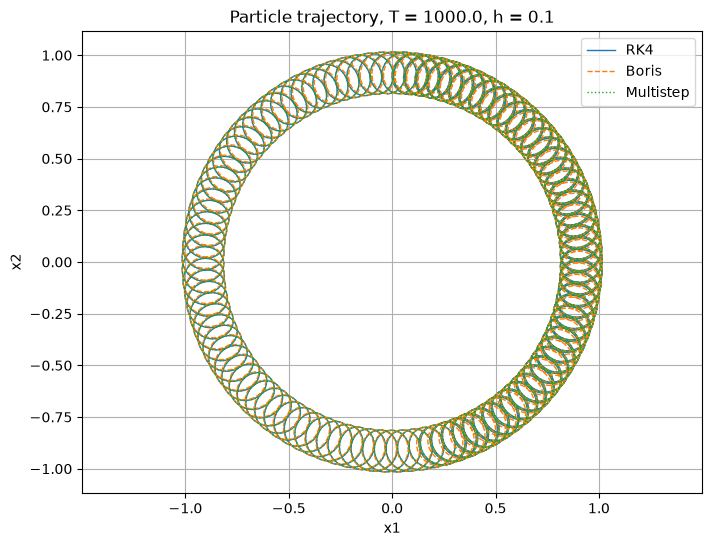

In [19]:
#Plotting trajectories for 2D case
X_rk4, V_rk4 = calculate_rk4(x0_2d, v0_2d, B_2d, nabla_U_2d, h, T)
X_boris, V_boris = calculate_boris(x0_2d, v0_2d, B_2d, nabla_U_2d, h, T)
X_multistep, V_multistep = calculate_multistep(x0_2d, v0_2d, B_2d, A_2d, nabla_U_2d, h, T)

plt.figure(figsize=(8, 6))

plot_trajectory(X_rk4, "RK4", "-")
plot_trajectory(X_boris, "Boris", "--")
plot_trajectory(X_multistep, "Multistep", ":")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"Particle trajectory, T = {T}, h = {h}")
plt.legend()
plt.axis("equal")
plt.grid()
plt.show()

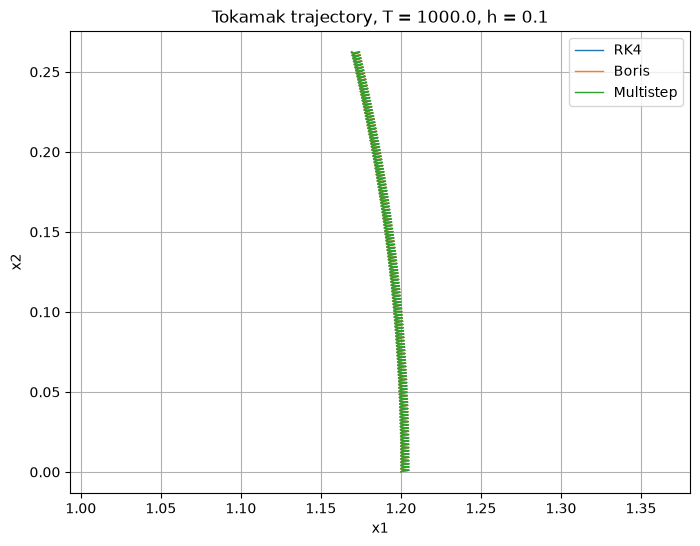

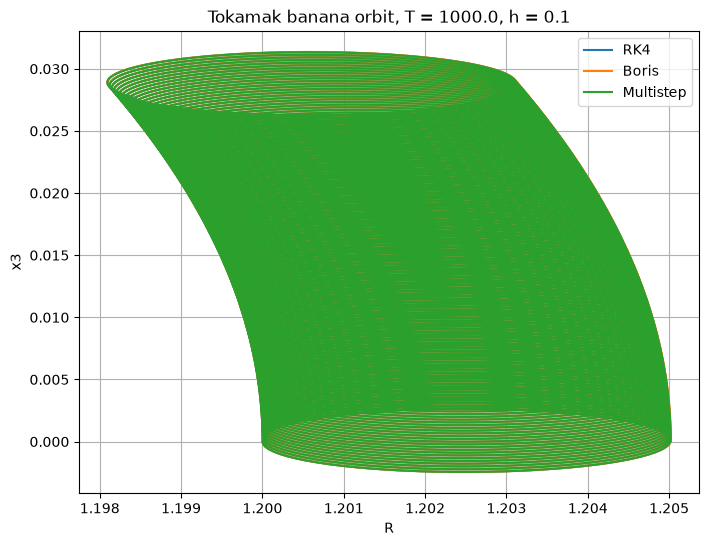

In [7]:
#Plotting trajectories for tokamak case:
X_rk4_tokamak, V_rk4_tokamak = calculate_rk4(x0_tokamak, v0_tokamak, B_tokamak, nabla_U_tokamak, h, T)
X_boris_tokamak, V_boris_tokamak = calculate_boris(x0_tokamak, v0_tokamak, B_tokamak, nabla_U_tokamak, h, T)
X_multistep_tokamak, V_multistep_tokamak = calculate_multistep(x0_tokamak, v0_tokamak, B_tokamak, A_tokamak, nabla_U_tokamak, h, T)

# Plot 1: (x1, x2)
plt.figure(figsize=(8, 6))

plot_trajectory(X_rk4_tokamak, "RK4")
plot_trajectory(X_boris_tokamak, "Boris")
plot_trajectory(X_multistep_tokamak, "Multistep")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"Tokamak trajectory, T = {T}, h = {h}")
plt.legend()
plt.axis("equal")
plt.grid()
plt.show()

# Plot 2: (R, x3)
plt.figure(figsize=(8, 6))

for X, label in [(X_rk4_tokamak, "RK4"), (X_boris_tokamak, "Boris"), (X_multistep_tokamak, "Multistep")]:    
    R = np.sqrt(X[:, 0]**2 + X[:, 1]**2)
    plt.plot(R, X[:, 2], label=label)

plt.xlabel("R")
plt.ylabel("x3")
plt.title(f"Tokamak banana orbit, T = {T}, h = {h}")
plt.legend()
plt.grid()
plt.show()

In [8]:
X_multistep_tokamak, V_multistep_tokamak = calculate_multistep(x0_tokamak, v0_tokamak, B_tokamak, A_tokamak, nabla_U_tokamak, h, T)

### A2: Referance solution and errors with methods from A1

In [86]:
# The reference solution using ODE45 and strict tolerances
def reference_solution(x0, v0, B, nabla_U, h, T):

    N = int(round(T / h))

    y0 = np.concatenate((x0, v0))
    t_span = (0, T)
    t_eval = np.linspace(0, T, N + 1)

    sol = solve_ivp(
        ode_system,
        t_span,
        y0,
        args=(B, nabla_U),
        t_eval=t_eval,
        method="RK45",
        rtol=1e-13,
        atol=1e-13)

    return sol.y[:3].T

def position_error(X, X_ref, axis=1):
    return np.linalg.norm(X - X_ref, axis=axis)

#error plotting:
def plot_position_error(X, X_ref, h, label):
    error = position_error(X, X_ref)
    t = np.arange(len(X)) * h
    
    plt.semilogy(t[1:], error[1:], label=label)

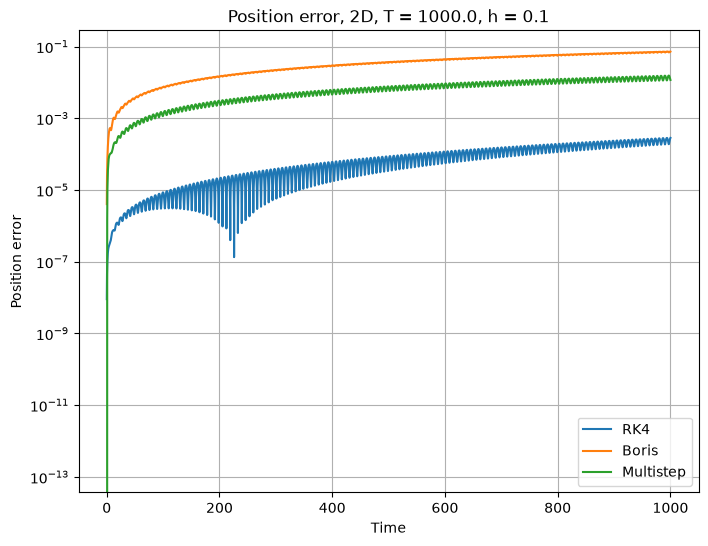

In [10]:
# Plotting position error for the 2D case
X_ref_2d = reference_solution(x0_2d, v0_2d, B_2d, nabla_U_2d, h, T)

plt.figure(figsize=(8, 6))

plot_position_error(X_rk4, X_ref_2d, h, "RK4")
plot_position_error(X_boris, X_ref_2d, h, "Boris")
plot_position_error(X_multistep, X_ref_2d, h, "Multistep")

plt.xlabel("Time")
plt.ylabel("Position error")
plt.title(f"Position error, 2D, T = {T}, h = {h}")
plt.legend()
plt.grid()
plt.show()

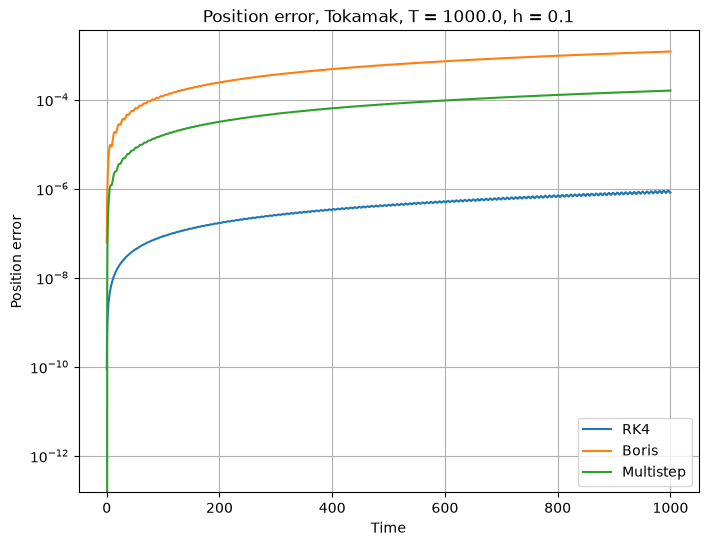

In [11]:
# Plotting positin error for the Tomak case
X_ref_tokamak = reference_solution(x0_tokamak, v0_tokamak, B_tokamak, nabla_U_tokamak, h, T)

plt.figure(figsize=(8, 6))

plot_position_error(X_rk4_tokamak, X_ref_tokamak, h, "RK4")
plot_position_error(X_boris_tokamak, X_ref_tokamak, h, "Boris")
plot_position_error(X_multistep_tokamak, X_ref_tokamak, h, "Multistep")

plt.xlabel("Time")
plt.ylabel("Position error")
plt.title(f"Position error, Tokamak, T = {T}, h = {h}")
plt.legend()
plt.grid()
plt.show()

### A3: Plot change in energy

In [12]:
def plot_energy_error(X, V, x0, v0, U, h, label):
    
    t = np.arange(len(X)) * h
    E0 = 0.5 * np.dot(v0, v0) + U(x0)

    kinetic = 0.5 * np.sum(V**2, axis=1)
    potential = np.array([U(x) for x in X])
    
    E = kinetic + potential
    
    error = np.abs(E - E0)
    
    plt.semilogy(t[1:], error[1:], label=label)

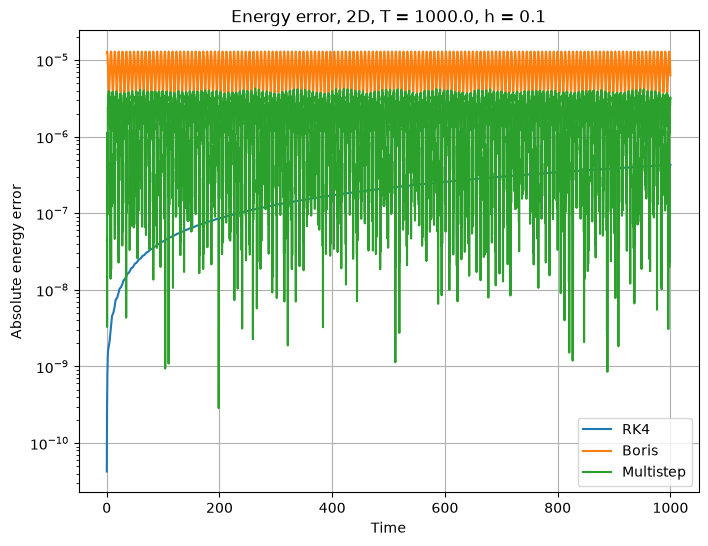

In [13]:
# 2D case for energy
X_rk4, V_rk4 = calculate_rk4(x0_2d, v0_2d, B_2d, nabla_U_2d, h, T)
X_boris, V_boris = calculate_boris(x0_2d, v0_2d, B_2d, nabla_U_2d, h, T)
X_multistep, V_multistep = calculate_multistep(x0_2d, v0_2d, B_2d, A_2d, nabla_U_2d, h, T)

plt.figure(figsize=(8, 6))

plot_energy_error(X_rk4, V_rk4, x0_2d, v0_2d, U_2d, h, "RK4")
plot_energy_error(X_boris, V_boris, x0_2d, v0_2d, U_2d, h, "Boris")
plot_energy_error(X_multistep, V_multistep, x0_2d, v0_2d, U_2d, h, "Multistep")

plt.xlabel("Time")
plt.ylabel("Absolute energy error")
plt.title(f"Energy error, 2D, T = {T}, h = {h}")
plt.legend()
plt.grid()
plt.show()

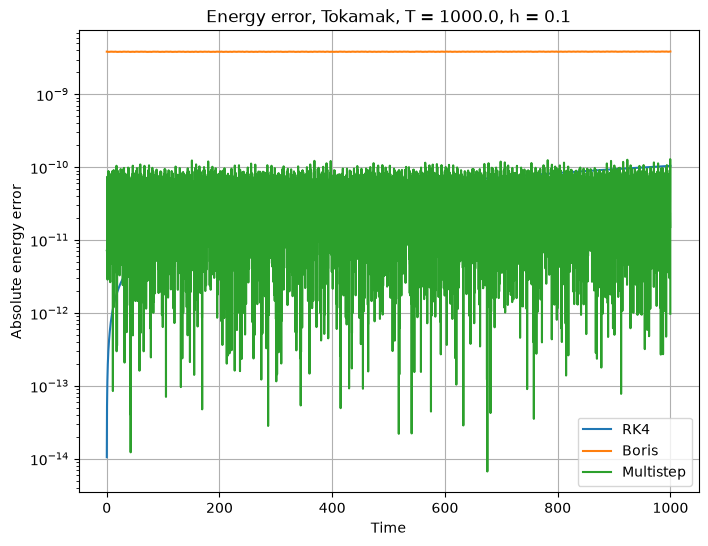

In [14]:
# Takamak case for energy
X_rk4_tokamak, V_rk4_tokamak = calculate_rk4(x0_tokamak, v0_tokamak, B_tokamak, nabla_U_tokamak, h, T)
X_boris_tokamak, V_boris_tokamak = calculate_boris(x0_tokamak, v0_tokamak, B_tokamak, nabla_U_tokamak, h, T)
X_multistep_tokamak, V_multistep_tokamak = calculate_multistep(x0_tokamak, v0_tokamak, B_tokamak, A_tokamak, nabla_U_tokamak, h, T)

plt.figure(figsize=(8, 6))

plot_energy_error(X_rk4_tokamak, V_rk4_tokamak, x0_tokamak, v0_tokamak, U_tokamak, h, "RK4")
plot_energy_error(X_boris_tokamak, V_boris_tokamak, x0_tokamak, v0_tokamak, U_tokamak, h, "Boris")
plot_energy_error(X_multistep_tokamak, V_multistep_tokamak, x0_tokamak, v0_tokamak, U_tokamak, h, "Multistep")

plt.xlabel("Time")
plt.ylabel("Absolute energy error")
plt.title(f"Energy error, Tokamak, T = {T}, h = {h}")
plt.legend()
plt.grid()
plt.show()

### Comments on the results from A
"Comment on the results and if you observed the expected behaviour the different methods. If
not, try to explain why":



# B

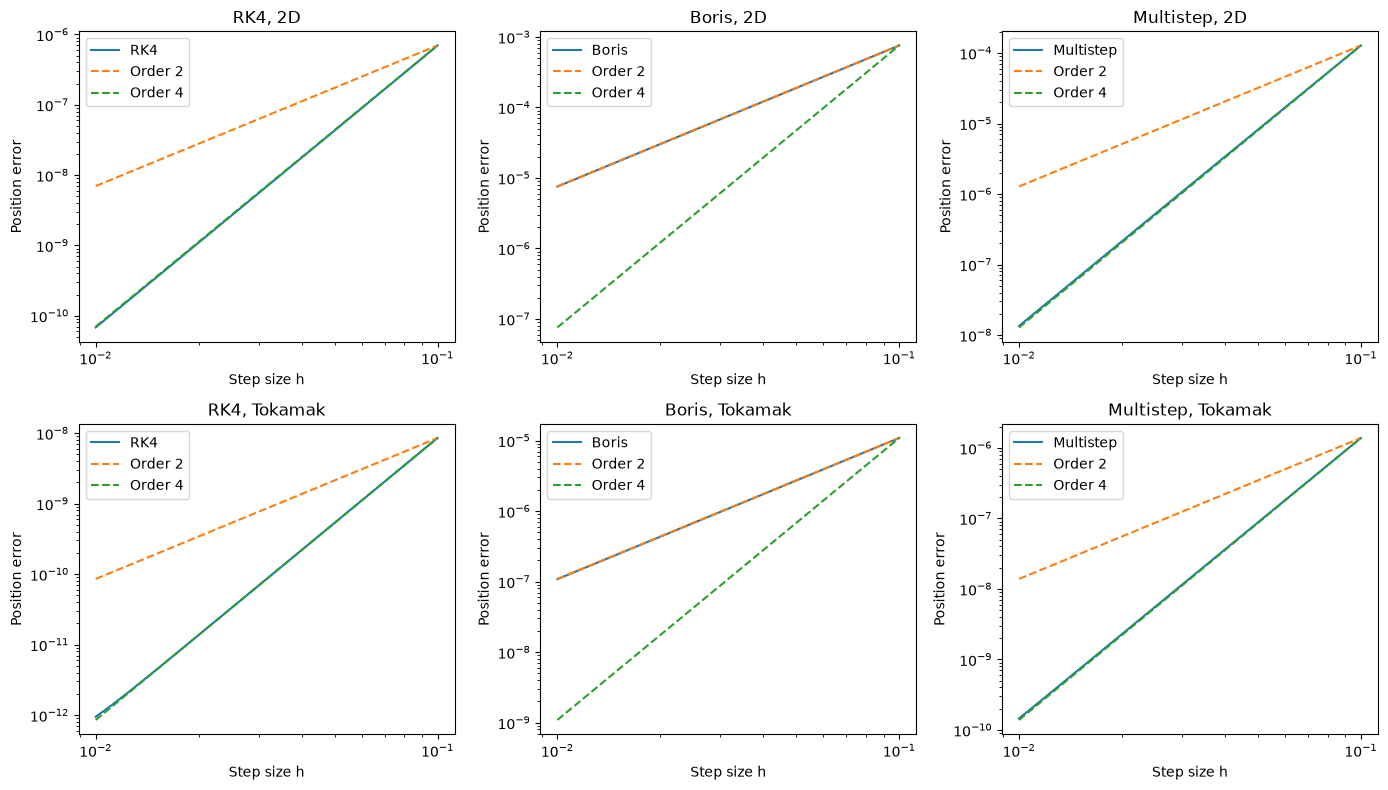

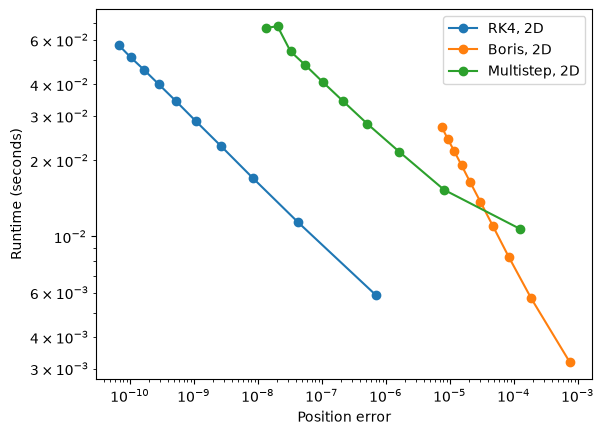

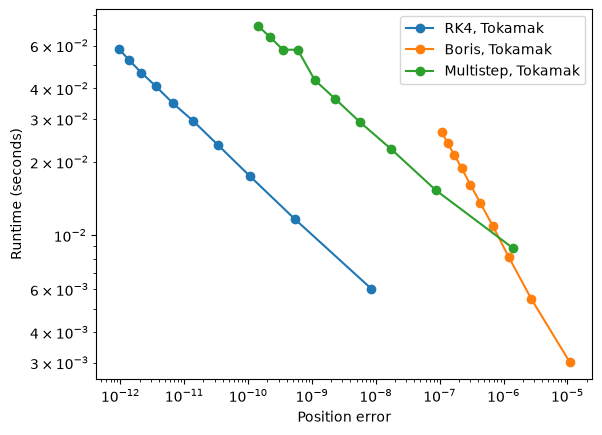

In [94]:



T = 10

def make_methods_funcs(x0, v0, B, A, nabla_U, T):
    return {
        "RK4": lambda h: calculate_rk4(x0, v0, B, nabla_U, h, T),
        "Boris": lambda h: calculate_boris(x0, v0, B, nabla_U, h, T),
        "Multistep": lambda h: calculate_multistep(x0, v0, B, A, nabla_U, h, T),
    }



methods_2d = make_methods_funcs(x0_2d, v0_2d, B_2d, A_2d, nabla_U_2d, T)
methods_tokamak = make_methods_funcs(x0_tokamak, v0_tokamak, B_tokamak, A_tokamak, nabla_U_tokamak, T)

h_ref = 1e-6
ref_pos_2d = reference_solution(x0_2d, v0_2d, B_2d, nabla_U_2d, h_ref, T)
ref_pos_tokamak = reference_solution(x0_tokamak, v0_tokamak, B_tokamak, nabla_U_tokamak, h_ref, T)

def measure_error(h_values: np.ndarray, method_str: str, is_tokamak: bool):
    method = methods_tokamak if is_tokamak else methods_2d
    x_ref = (ref_pos_tokamak if is_tokamak else ref_pos_2d)[-1] # Comparing the last position
    errors = []
    runtimes = []
    for h_i in h_values:
        start_time = perf_counter()
        x, v = method[method_str](h_i)
        runtimes.append(perf_counter() - start_time)
        errors.append(np.linalg.norm(x[-1] - x_ref))
    return np.array(errors), np.array(runtimes)





def plot_errors(h_values: np.ndarray):
    h_values = np.sort(h_values)
    methods = ["RK4", "Boris", "Multistep"]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))

    for row, is_tokamak in enumerate([False, True]):
        for col, method in enumerate(methods):
            ax = axes[row, col]
            error, _ = measure_error(h_values, method, is_tokamak=is_tokamak)
            ax.loglog(h_values, error, label=method)

            # Reference lines are the lines representing the order of numerical error,
            # so if the error is on the order of h**n then it would roughly follow the y = h**n curve
            # (in a loglog plot it wil follow a linear curve with the same slope: log(C * h**n) = log(C) + log(h**n) = log(C) + n * log(h))
            for p in [2, 4]:
                # Make the reference start at the same spot as to make only the order mater, not the constant
                reference = error[-1] * (h_values / h_values[-1])**p
                ax.loglog(h_values, reference, "--", label=f"Order {p}")

            system = "Tokamak" if is_tokamak else "2D"
            ax.set_title(f"{method}, {system}")
            ax.set_xlabel("Step size h")
            ax.set_ylabel("Position error")
            ax.legend()
            

    plt.tight_layout()
    plt.show()


def plot_runtime(h_values: np.ndarray, is_tokamak=False):
    for method in ["RK4", "Boris", "Multistep"]:
        errors, runtimes = measure_error(h_values, method, is_tokamak=is_tokamak)
        system = "Tokamak" if is_tokamak else "2D"
        plt.loglog(errors, runtimes, "-o", label=method + ", " + system)


    plt.xlabel("Position error")
    plt.ylabel("Runtime (seconds)")
    plt.legend()
    plt.show()

N_values = np.arange(100, 1001, 100)
h_values = T / N_values
plot_errors(h_values)



plot_runtime(h_values, is_tokamak=False)
plot_runtime(h_values, is_tokamak=True)



## Explanation of the plots

In the first plots we can see that RK4 har an error of order 4, Boris has an error of order 2 and multistep's error has an order of 4, as the slopes are almost identical to their respective reference lines. Here we only care about the slopes as we are looking at the order of error, and in a loglog plot we know that if the error is $e(h) \approx C h^p$ then $log(e) \approx log(C) + p * log(h)$, and this will grow linearly in a loglog plot with the slope as the order $p$ of the error.

The convergens order however doesn't nesesarily imply a smaller error, as it also depends on the constant $C$. That might be big compared to some other method even for some small $h$. If the methods are of the same order the error ratio would approach the ratio of theyer constants, however for differente orders, the higher order methods would eventualy outperform the lower order method as $h$ decreses.

Now for the other plots, we see that the system (tokamak or 2d) doesnt affect the relationship between the methds, so for this explanation i will refere to the Tokamak version. We can see that for the chosen $h$-interval and RK4 looks substantialy more efficient relative to its error, than the multistep method and Boris. Considering Boris is a second order method this makes sense. The multistep method is also forth order however, but it is also more computationaly heavy as it computes the vector potentials and solves for the first 8 values at each simulation. RK4 is most efficient over these error ranges, but the performance of Multistep and Boris depends on your requirements. Multistep is beter for stricter tolerences, but Boris is faster if you have more error tolerance.

This beter performance for RK4 doesn't account for a biger timeinterval where the conservation of energy maters.